# Week 9 Class Demo 1: Linear Regression for Healthcare Cost Forecasting
## Predicting healthcare cost

### Business scenario
A hospital operations team wants an early estimate of healthcare cost to support budgeting, cost forecasting, and identifying where further operational analysis may be useful. The model is not a clinical decision rule.

## Learning and review resources

Use the resources in this order. This notebook is the main guided-review resource.

1. [Lecture 15 recording](https://nait.video.yuja.com/V/Video?v=1347385&node=7565682&a=55881620)
2. [Lecture 15 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture15_beginning_regression_part_1.ipynb)
3. [Lecture 15–16 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture15_16_workbook.ipynb)
4. [Supplementary least-angle regression PDF](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture16_LEAST_%20ANGLE_REGRESSION.pdf)
5. [*Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/): Chapter 4, Chapter 5, and Chapter 7 through the NAIT O’Reilly subscription.

### Autonomous-learning routine
1. Read the theory before running code.
2. Predict what the output will mean.
3. Run the supplied code. You are not expected to write the model from scratch.
4. Interpret the output in business language.
5. Open the collapsible answer only after drafting your response.
6. Ask whether the evidence supports a decision, not merely whether the code runs.

## 🎯 Learning Objectives

By the end of this class demo, you should be able to:

1. **Explain the purpose of Linear Regression** and identify business problems where it can be used to predict a continuous numerical outcome.

2. **Identify the target (`y`) and predictor variables (`X`)** from a business dataset and explain why particular variables should or should not be included.

3. **Build and run a Linear Regression model** using a provided Python/scikit-learn workflow without needing to memorize the code.

4. **Interpret the intercept and regression coefficients in business language**, including the direction, magnitude, and units of a relationship.

5. **Distinguish association from causation** and avoid making causal claims based only on regression coefficients.

6. **Evaluate regression performance** using:
   - Mean Absolute Error (MAE)
   - Mean Squared Error (MSE)
   - Root Mean Squared Error (RMSE)
   - R² Score

7. **Compare a regression model with a simple baseline** and determine whether the model provides meaningful predictive improvement.

8. **Use residuals and visualizations** to identify possible model limitations, unusual predictions, and patterns the model may not capture.

9. **Recognize the risks of extrapolation** when a model is asked to predict cases that are very different from the data used to train it.

10. **Translate model results into a business recommendation** by balancing predictive performance, interpretability, limitations, and the intended use of the model.

11. **Apply the Linear Regression workflow to a new business problem**, such as predicting weekly sales from advertising spending.

12. **Transfer the same modelling and interpretation process to Assignment 1**, where you will make and justify your own modelling decisions.

> ### 💡 BBA Focus
> You are **not expected to memorize Python modelling code**.  
> Your primary responsibility is to understand the modelling process and be able to explain:
>
> **What is being predicted? → What information is being used? → How well does the model perform? → What do the results mean? → What business decision can reasonably be supported?**
>
> Generative AI can help you develop or troubleshoot code, but **you must be able to interpret the output, justify your modelling choices, identify limitations, and communicate the results in business language.**

## Connection to Assignment 1: Regression Modelling & Evaluations

Assignment 1 uses a different business context: predicting **`wage_eur` for FIFA soccer players**. The modelling workflow in this healthcare demonstration transfers directly, but your Assignment 1 decisions must be based on the FIFA data rather than copied from this notebook.

Assignment 1 emphasizes the quality of your **decisions, explanations, and iteration**, not simply finding the model with the best score. Use this demo as a worked example of how to:

1. load and preview a dataset;
2. clean and transform relevant fields;
3. select features using evidence and domain logic;
4. create and justify a train-test split;
5. train at least one regression model;
6. evaluate the model with appropriate metrics;
7. identify a limitation or unexpected result and revise the approach;
8. explain what the final result means in business language.

> **Academic-work reminder:** Generative AI may help you understand syntax or troubleshoot code, but your submitted notebook must reflect your group's own choices, outputs, interpretation, and reflection. Generic explanations that do not match your code and results will not demonstrate the required learning.

## What to check before modelling
1. Does the number of rows and columns look reasonable?
2. Is `health_cost` present and numeric?
3. Which field is only an identifier?
4. Which field needs encoding?
5. What business question will the model answer?

The goal is not to memorize code. The goal is to connect each line of code to an analytical decision.

## Theory: the linear model

Regression predicts a continuous quantity such as dollars, cost, demand, or revenue.

$$\hat{y}=b_0+b_1x_1+\cdots+b_px_p$$

- $\hat{y}$ is a prediction.
- $b_0$ is the intercept.
- $b_j$ is the estimated change in the prediction associated with a one-unit increase in $x_j$, holding other included variables constant.
- A residual is $y-\hat{y}$.

A coefficient is an adjusted association within the fitted model. It is not proof that changing a feature will cause the target to change. BBA students should focus on magnitude, units, decision relevance, uncertainty, and limitations rather than memorizing syntax.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE = 42
pd.set_option("display.precision", 2)

In [107]:
# Load the same healthcare dataset used in Week 8.
# Keep the CSV in the same folder as this notebook.
from pathlib import Path

DATA_FILE = Path("ClassDemo_health_data.csv")
df = pd.read_csv(DATA_FILE)
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
df.head()

Rows: 65,000; columns: 11


,patient_id,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol,health_cost
0,P000001,51,23.1,118,68,75,2.1,7.6,No,211,6288
1,P000002,31,19.5,88,75,78,6.9,6.6,No,141,4930
2,P000003,22,24.2,112,67,74,2.2,5.9,No,185,4877
3,P000004,23,31.1,88,57,82,4.1,7.7,No,144,5148
4,P000005,49,31.3,132,60,66,4.1,7.4,Yes,217,6505


## Dataset and responsible-use boundary

This notebook reuses **`ClassDemo_health_data.csv`** from Week 8 so that the emphasis shifts from understanding and preparing data to building and interpreting regression models.

| Field | Role in this notebook |
|---|---|
| `patient_id` | Identifier; excluded from modelling |
| `age` | Numeric predictor |
| `bmi` | Numeric predictor |
| `systolic_bp`, `diastolic_bp` | Numeric predictors |
| `resting_hr` | Numeric predictor |
| `exercise_hours`, `sleep_hours` | Numeric predictors |
| `smoker` | Categorical predictor encoded as 0/1 |
| `cholesterol` | Numeric predictor |
| `health_cost` | Continuous target predicted in dollars |

The file is teaching data. Model output supports learning about business analytics and should not be treated as clinical or insurance-pricing evidence.

In [44]:
print(df.shape)
df.describe().T

(65000, 11)


,count,mean,std,min,25%,50%,75%,max
age,65000.0,49.24,18.19,18.0,34.0,49.0,65.0,80.0
bmi,65000.0,27.54,5.13,16.5,24.0,27.5,31.0,46.0
systolic_bp,65000.0,114.75,13.06,88.0,105.0,115.0,124.0,168.0
diastolic_bp,65000.0,69.84,7.97,52.0,64.0,70.0,75.0,103.0
resting_hr,65000.0,75.61,7.86,45.0,70.0,76.0,81.0,107.0
exercise_hours,65000.0,2.98,2.09,0.0,1.4,2.5,4.0,12.0
sleep_hours,65000.0,7.01,1.05,3.5,6.3,7.0,7.7,10.0
cholesterol,65000.0,180.09,32.37,105.0,158.0,180.0,202.0,312.0
health_cost,65000.0,6350.11,1447.77,1301.0,5361.0,6327.0,7326.0,13337.0


### Check-in 1: frame the problem
What is the target? Give one decision the prediction could inform and one decision it should not make independently.

<details>
<summary><strong>Model answer</strong></summary>

The target is completed healthcare cost in dollars. The estimate could support aggregate cost planning, but it should not independently determine clinical, coverage, or pricing.

</details>

## Simple linear regression
We begin with severity alone so the fitted relationship is visible. A test set gives evidence on rows not used to estimate the line.

In [48]:
from sklearn.linear_model import LinearRegression
X = df[["age"]]
y = df["health_cost"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
simple = LinearRegression().fit(X_train,y_train)
pred_simple = simple.predict(X_test)
print("Intercept:", simple.intercept_)
print("Age coefficient:", simple.coef_[0])

Intercept: 4465.880931195555
Age coefficient: 38.18703744065421


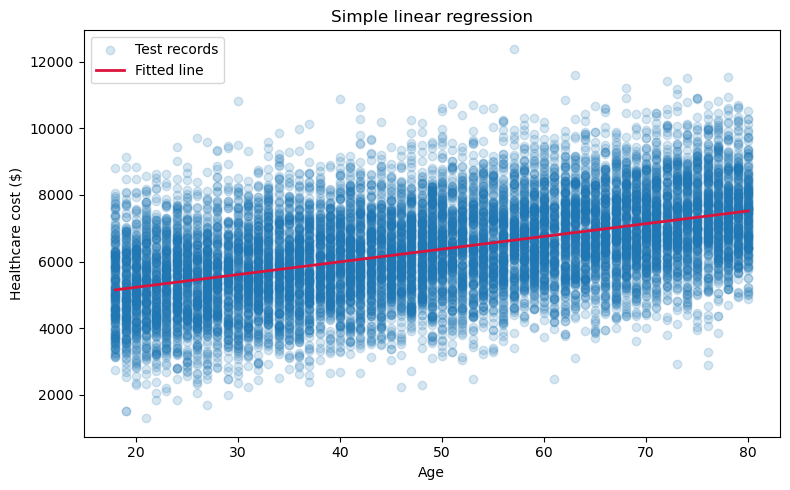

In [49]:
grid=pd.DataFrame({"age":np.linspace(X_test["age"].min(),X_test["age"].max(),100)})
plt.figure(figsize=(8,5)); plt.scatter(X_test["age"],y_test,alpha=.18,label="Test records"); plt.plot(grid["age"],simple.predict(grid),color="crimson",lw=2,label="Fitted line"); plt.xlabel("Age"); plt.ylabel("Healthcare cost ($)"); plt.title("Simple linear regression"); plt.legend(); plt.tight_layout(); plt.show()

### Check-in 2: interpretation
Interpret the severity coefficient in one sentence. Why is a causal statement inappropriate?

<details>
<summary><strong>Model answer</strong></summary>

A one-point higher severity score is associated with the displayed increase in predicted healthcare cost dollars in this one-feature model. The relationship is not causal because the analysis is observational and important factors may be omitted.

</details>

## Multiple linear regression
Each coefficient is interpreted while holding the other included variables constant. Adding predictors may improve prediction, but it does not eliminate omitted-variable concerns or guarantee stable coefficients.

In [53]:
model_df=df.copy()
model_df["smoker_yes"]=(model_df["smoker"].str.strip().str.lower()=="yes").astype(int)
features=["age","bmi","systolic_bp","diastolic_bp","resting_hr","exercise_hours","sleep_hours","smoker_yes","cholesterol"]
X=model_df[features]; y=model_df["health_cost"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
model=LinearRegression().fit(X_train,y_train)
pred=model.predict(X_test)
coefs=pd.DataFrame({"Feature":features,"Coefficient":model.coef_})
coefs.sort_values("Coefficient")

,Feature,Coefficient
5,exercise_hours,-89.15
6,sleep_hours,-76.55
3,diastolic_bp,-0.40
4,resting_hr,-0.34
8,cholesterol,0.12
2,systolic_bp,8.77
0,age,34.22
1,bmi,119.89
7,smoker_yes,1471.79


### Check-in 3: manager-ready coefficients
Choose two coefficients. State direction, magnitude, unit, the holding-constant condition, and a caution against causal interpretation.

<details>
<summary><strong>Model answer</strong></summary>

Example: Holding the other included variables constant, one additional comorbidity is associated with the displayed change in predicted healthcare cost dollars. This is an adjusted association in synthetic data, not proof that the comorbidity causes the change.

</details>

## Evaluation theory

- **MAE** is the average absolute error in dollars and is easy to explain.
- **MSE** squares errors and strongly penalizes large misses.
- **RMSE** returns squared error to dollars while remaining sensitive to large misses.
- **R²** measures improvement relative to a constant-mean reference. It is not “percent accurate” and can be negative.

A model must be compared with a meaningful baseline. No single metric proves business usefulness.

In [57]:
def regression_metrics(y_true, prediction, model_name):
    return pd.Series({"Model":model_name,"MAE":mean_absolute_error(y_true,prediction),"MSE":mean_squared_error(y_true,prediction),"RMSE":mean_squared_error(y_true,prediction)**0.5,"R2":r2_score(y_true,prediction)})

In [58]:
baseline=np.repeat(y_train.mean(),len(y_test))
results=pd.DataFrame([regression_metrics(y_test,baseline,"Training-mean baseline"),regression_metrics(y_test,pred,"Multiple linear regression")]).set_index("Model")
results

,MAE,MSE,RMSE,R2
Model,,,,
Training-mean baseline,1160.06,2.10e+06,1449.77,-1.93e-04
Multiple linear regression,719.90,8.16e+05,903.49,6.12e-01


### Check-in 4: performance briefing
Explain typical error, improvement over baseline, and one additional analysis required before operational use.

<details>
<summary><strong>Model answer</strong></summary>

Use MAE to describe the typical miss in dollars and compare it directly with baseline MAE. Before use, request subgroup error analysis, stability over time, data-quality checks, and a clear workflow describing how predictions influence decisions.

</details>

## Residual diagnostics
A residual plot should be an unstructured cloud around zero. Curvature, widening spread, or extreme misses may signal nonlinearity, unequal error variance, omitted structure, or unusual cases.

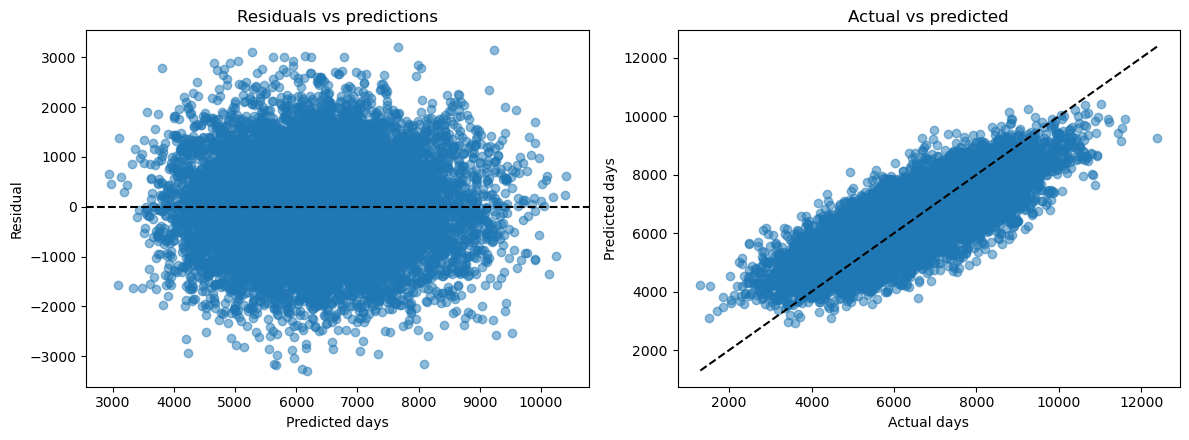

In [62]:
res=y_test-pred
fig,ax=plt.subplots(1,2,figsize=(12,4.5)); ax[0].scatter(pred,res,alpha=.5); ax[0].axhline(0,color="black",ls="--"); ax[0].set(xlabel="Predicted days",ylabel="Residual",title="Residuals vs predictions"); ax[1].scatter(y_test,pred,alpha=.5); lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max()); ax[1].plot([lo,hi],[lo,hi],"k--"); ax[1].set(xlabel="Actual days",ylabel="Predicted days",title="Actual vs predicted"); plt.tight_layout(); plt.show()

## Intriguing Example 1: The Health-Cost Detective

A manager notices that patients with higher cholesterol appear to have higher healthcare costs. The manager concludes:

> “Lowering cholesterol will reduce cost by exactly the fitted coefficient.”

This is a **correlation-to-causation trap**.

### Investigation steps
1. Fit a simple model using cholesterol alone.
2. Fit a multiple model that also includes other measured characteristics.
3. Compare the cholesterol coefficients.
4. Ask why the coefficient changes.
5. Decide what may be said and what may not be said.

A changing coefficient demonstrates that a relationship can depend on which other variables are included. It does not reveal the complete causal story.

In [64]:
# Compare an unadjusted and adjusted cholesterol coefficient.
cholesterol_only = LinearRegression().fit(model_df[["cholesterol"]], model_df["health_cost"])
adjusted_model = LinearRegression().fit(model_df[features], model_df["health_cost"])

comparison_coefficients = pd.Series({
    "Cholesterol-only coefficient": cholesterol_only.coef_[0],
    "Adjusted cholesterol coefficient": adjusted_model.coef_[features.index("cholesterol")]
})
comparison_coefficients

Cholesterol-only coefficient        20.16
Adjusted cholesterol coefficient     0.10
dtype: float64

### Detective check-in
Why might the two coefficients differ? Can either coefficient prove how much cost would fall if cholesterol were reduced?

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

The adjusted model compares records after accounting for the other included predictors, while the simple model does not. The coefficient can change because cholesterol is related to other measured characteristics. Neither model proves the effect of an intervention because this observational prediction exercise does not establish causation.

</details>

## Intriguing Example 2: The “What-if” Button

Managers often ask counterfactual questions such as, “What happens if this one field changes?” A model can calculate a **scenario estimate**, but that estimate is not automatically a causal forecast.

We create two otherwise identical synthetic profiles. Only smoking status changes. The difference between predictions equals the fitted smoker coefficient because this is a linear model.

### Interpretation challenge
The model is answering: “How do predictions differ when the encoded field differs, holding the included values fixed?” It is **not** proving what would happen to a real person after a behaviour change.

In [68]:
profile = {
    "age": 45, "bmi": 27.5, "systolic_bp": 128, "diastolic_bp": 82,
    "resting_hr": 72, "exercise_hours": 3.0, "sleep_hours": 7.0,
    "smoker_yes": 0, "cholesterol": 190
}
scenario_non_smoker = pd.DataFrame([profile])
scenario_smoker = scenario_non_smoker.copy()
scenario_smoker["smoker_yes"] = 1

pred_non_smoker = model.predict(scenario_non_smoker)[0]
pred_smoker = model.predict(scenario_smoker)[0]
print(f"Scenario A prediction: ${pred_non_smoker:,.0f}")
print(f"Scenario B prediction: ${pred_smoker:,.0f}")
print(f"Model-based difference: ${pred_smoker-pred_non_smoker:,.0f}")

Scenario A prediction: $6,043
Scenario B prediction: $7,515
Model-based difference: $1,472


### Boardroom check-in
Which phrase is defensible?

- **Claim A:** “Smoking causes the displayed cost increase.”
- **Claim B:** “Within this fitted model, otherwise identical profiles receive predictions that differ by the displayed amount when the smoking indicator changes.”

What additional evidence would be needed to support a causal claim?

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

Claim B accurately describes the model calculation. A causal claim would need a research design and evidence capable of separating the effect of smoking from confounding factors, measurement limitations, and selection effects.

</details>

## Intriguing Example 3: When a Model Gives an Impossible Answer

Linear regression can extrapolate beyond the region represented in the training data. It can even produce a negative prediction for a target that cannot logically be negative.

### Student challenge
Create an extreme profile, inspect the prediction, and decide whether the model should be trusted there. If the prediction remains positive, make the profile more extreme. The learning objective is not to create a realistic record; it is to expose the danger of extrapolation.

In [72]:
extreme_profile = pd.DataFrame([{
    "age": 5, "bmi": 8, "systolic_bp": 55, "diastolic_bp": 30,
    "resting_hr": 25, "exercise_hours": 40, "sleep_hours": 16,
    "smoker_yes": 0, "cholesterol": 60
}])
extreme_prediction = model.predict(extreme_profile)[0]
print(f"Extreme-profile prediction: ${extreme_prediction:,.0f}")
print("Inside observed age range:", df["age"].min() <= extreme_profile.loc[0,"age"] <= df["age"].max())
print("Inside observed BMI range:", df["bmi"].min() <= extreme_profile.loc[0,"bmi"] <= df["bmi"].max())

Extreme-profile prediction: $-2,269
Inside observed age range: False
Inside observed BMI range: False


### Risk check-in
Even if the result is numerically possible, why is it unreliable? Suggest one business control for out-of-range inputs.

<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

The profile lies outside the region used to fit the model, so the linear relationship is being extended without supporting observations. A workflow could validate input ranges, flag out-of-distribution records, cap the scope of use, or route unusual cases to manual review.

</details>

## Optional Assignment 1 Twist: “The Superstar Problem”

In the FIFA wage assignment, a few superstar players may earn far more than typical players. Ask:

1. Does the model systematically underpredict the highest wages?
2. Is MAE hiding a small number of very large misses?
3. Would a log transformation of `wage_eur` change the modelling question?
4. Should an employer use one model for all players, or investigate segments?

This is an interpretation exercise. Any transformation used in Assignment 1 must be explained and evaluated on the group's own results.

## Student Try-It: A Different Linear Regression Example — Advertising Spend and Sales

This short exercise intentionally leaves healthcare behind. Imagine you are a marketing analyst deciding whether digital advertising spend helps forecast weekly sales.

### Scenario
A small retailer has 20 weeks of observations containing:
- **`ad_spend_k`**: digital advertising spend in thousands of dollars
- **`sales_k`**: weekly sales in thousands of dollars

The code is mostly supplied. Your job is to **run it, read the output, and explain the business meaning**.

### Steps
1. Run the supplied data cell.
2. Create `X` from advertising spend and `y` from sales.
3. Split the data into training and test sets.
4. Fit `LinearRegression`.
5. Predict test-set sales.
6. Interpret the slope and MAE.
7. Decide whether the model alone proves that more advertising *causes* more sales.

> **Assignment 1 connection:** This is the same workflow you can transfer to `wage_eur`: define a continuous target, choose plausible predictors, split, fit, evaluate, and interpret.

In [77]:
# Small self-contained dataset: easy to paste into Google Colab
marketing = pd.DataFrame({
    "ad_spend_k": [2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21],
    "sales_k":    [24,26,27,31,30,34,36,35,40,42,41,45,47,46,50,52,51,55,58,59]
})
marketing.head()

,ad_spend_k,sales_k
0,2,24
1,3,26
2,4,27
3,5,31
4,6,30


In [78]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X_mkt = marketing[["ad_spend_k"]]
y_mkt = marketing["sales_k"]

X_train_mkt, X_test_mkt, y_train_mkt, y_test_mkt = train_test_split(
    X_mkt, y_mkt, test_size=0.25, random_state=42
)

mkt_model = LinearRegression()
mkt_model.fit(X_train_mkt, y_train_mkt)
mkt_pred = mkt_model.predict(X_test_mkt)

print(f"Intercept: {mkt_model.intercept_:.2f}")
print(f"Slope: {mkt_model.coef_[0]:.2f}")
print(f"Test MAE: {mean_absolute_error(y_test_mkt, mkt_pred):.2f} thousand dollars")
print(f"Test R²: {r2_score(y_test_mkt, mkt_pred):.3f}")

Intercept: 20.47
Slope: 1.82
Test MAE: 0.45 thousand dollars
Test R²: 0.997


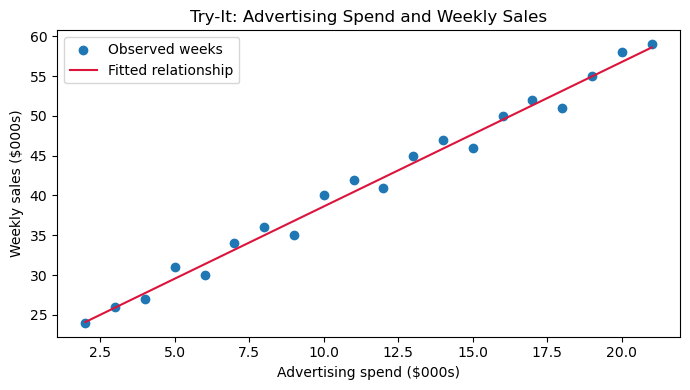

In [79]:
plt.figure(figsize=(7,4))
plt.scatter(marketing["ad_spend_k"], marketing["sales_k"], label="Observed weeks")
x_line = pd.DataFrame({"ad_spend_k": np.linspace(2,21,100)})
plt.plot(x_line["ad_spend_k"], mkt_model.predict(x_line), color="crimson", label="Fitted relationship")
plt.xlabel("Advertising spend ($000s)")
plt.ylabel("Weekly sales ($000s)")
plt.title("Try-It: Advertising Spend and Weekly Sales")
plt.legend(); plt.tight_layout(); plt.show()

### Your interpretation questions
1. What does the slope mean in **business units**?
2. What does MAE mean here?
3. If next week's advertising budget is **$15,000**, what sales value does the model predict?
4. Does the relationship prove that increasing advertising by $1,000 will *cause* sales to rise by exactly the slope?
5. Name one omitted factor that might affect weekly sales.

In [81]:
# Change this value and rerun the cell.
new_ad_spend_k = 15
new_week = pd.DataFrame({"ad_spend_k": [new_ad_spend_k]})
new_sales_pred = mkt_model.predict(new_week)[0]
print(f"With ${new_ad_spend_k:,.0f}k advertising spend, predicted weekly sales = ${new_sales_pred:,.1f}k")

With $15k advertising spend, predicted weekly sales = $47.7k


<details>
<summary><strong>Reveal suggested interpretation</strong></summary>

1. The slope is the estimated change in predicted weekly sales, in thousands of dollars, associated with an additional $1,000 of advertising spend within this fitted example.
2. MAE is the average absolute difference between predicted and actual test-week sales, measured in thousands of dollars.
3. Use the displayed prediction from the final code cell.
4. No. This simple observational relationship supports prediction, not a causal advertising-effect claim.
5. Plausible omitted factors include seasonality, promotions, competitor activity, product availability, holidays, or pricing.

</details>

## BBA Interpretation Lab
Work in pairs. Draft each answer before expanding the solution.

1. A manager says, “The R² is high, so the model is accurate for every patient.” What is wrong?
2. The model beats the baseline on MAE but makes several large errors. How would you explain value and risk?
3. The care-coordination coefficient is negative. What does it mean, and what should management avoid concluding?
4. A positive weekend coefficient appears. Should the hospital immediately add weekend staff?
5. Two models have almost identical MAE, but one is easier to explain. Which would you favour for an early prototype?
6. Can these regression metrics establish ROI?
7. Why can average test performance hide an operational problem?
8. Communicate performance without using “good,” “bad,” or “accurate.”

<details>
<summary><strong>Model answer</strong></summary>

1. R² summarizes improvement over a mean reference across the sample; it does not show that every prediction is close. Review MAE, RMSE, residuals, and relevant groups.

2. Lower MAE suggests planning value for the typical case, but large misses can create capacity risk. Report both typical error and the distribution of large residuals.

3. Holding other inputs constant, a higher coordination score is associated with the displayed reduction in predicted dollars. Do not claim that increasing the score will cause that reduction.

4. No. A staffing change requires real operational data, cost and demand analysis, uncertainty assessment, and preferably evidence that the intervention changes outcomes.

5. Prefer the more interpretable model when the performance difference is not operationally meaningful, because communication and governance are also costs.

6. No. ROI requires translating improved predictions into benefits and comparing them with implementation, training, maintenance, and governance costs.

7. Averages may conceal systematically larger errors for certain units, conditions, or time periods.

8. Example: “On held-out data, predictions differed from actual stays by an average absolute amount equal to the reported MAE in dollars.”

</details>

## Assignment 1 Transfer Guide: Linear Regression

Use the questions below when adapting this workflow to Assignment 1. These are guidance prompts, not answers for the FIFA dataset.

### Before modelling
- What makes `wage_eur` a regression target?
- Which columns are identifiers, descriptive labels, or possible predictors?
- Which features would be unavailable at the time the prediction is supposed to be made?
- Are missing values concentrated in potentially useful fields?
- Are any numerical features highly skewed or dominated by unusual values?

### Feature selection
- What business or soccer-domain logic supports each selected feature?
- Does the correlation analysis reveal redundant predictors?
- Are you keeping a feature only because it has a strong correlation, or can you explain why the relationship is plausible?
- Could any field leak information that effectively reveals wage or value?

### Model interpretation
- Interpret each important coefficient in euros while holding the other included predictors constant.
- Do not describe a coefficient as causal.
- Decide whether the intercept has a meaningful real-world interpretation.
- Use residuals to identify where the linear model tends to underpredict or overpredict.

### Evidence to retain in the assignment notebook
- A concise initial-data review
- A written justification for cleaning and feature decisions
- The train-test split and its rationale
- A baseline comparison
- MAE, MSE or RMSE, and R² with plain-language interpretations
- At least one visualization that influenced a decision
- A documented revision prompted by evidence
- A final recommendation that includes a limitation

## Assignment 1 Reflection Checklist

Before submitting, confirm that Part 2 matches the actual code and output in Part 1.

- **Initial approach:** State the original hypothesis for predicting `wage_eur`.
- **Data preparation:** Name the fields changed, removed, or imputed and explain why.
- **Feature selection:** Connect selected features to evidence and domain logic.
- **Modelling techniques:** Explain why each model was attempted.
- **Evaluation strategy:** Interpret metric values in euros and relative to a baseline.
- **Challenges and surprises:** Describe a specific result, not a generic difficulty.
- **Visual insight:** Explain how one visualization changed or confirmed a decision.
- **Final outcome:** Report held-out test performance, confidence, and limitations.

### Strong reflection pattern
**Evidence → decision → result → revision.**  
Example structure: “The analysis showed ____. Therefore, the group decided to ____. This changed the result by ____. The next revision would be ____.”

### Final technical checks
- Rename the submission using the required group naming convention.
- Restart the kernel and run all cells from top to bottom.
- Remove unexplained errors and unused experimental output.
- Ensure every written claim agrees with the displayed result.
- Do not claim that the model predicts every player's wage precisely.

## Exit ticket
Write a five-sentence management note stating the target, the most understandable metric, one useful insight, one material limitation, and the next analysis you recommend.